## Lock in the real-world graph: Terneuzen
In this notebook, we set up a basic simulation where 20 vessels cross a lock complex in a real-world graph. We consider the entire Terneuzen Lock Complex, consisting of three lock chambers. We account for a tidal water level and saltwater intrusion.

![OpenTNSim-Terneuzen](figures/0212_Terneuzen.jpg)

In [1]:
# package(s) used for creating and geo-locating the graph
import networkx as nx
from shapely.geometry import Point, Polygon
import geopandas as gpd

# package(s) related to the simulation (creating the vessel, running the simulation)
import datetime
import simpy
import opentnsim

# import of basic core mixins and utils for creating objects, inspecting the output and plotting
from opentnsim.core import ExtraMetadata
from opentnsim.core.utils import create_object, generate_vessels_from_distribution

# import of mixins and utils important for energy and fuel consumption
from opentnsim.energy.mixins import ConsumesEnergy

# import of utils for graph construction and visualization
from opentnsim.graph import FIS as fis
from opentnsim.graph.calculations import merge_two_consecutive_edges_based_on_shared_node
from opentnsim.graph.utils import get_closest_node_to_geometry, find_nodes_in_a_polygon
from opentnsim.graph.visualizations import plot_graph_folium, visualize_geometry_polygon_in_folium_plot

# import of mixins and utils important for locking
from opentnsim.lock import IsLockChamber, IsLockWaitingArea, IsLockComplex, LockComplexTraversable
from opentnsim.lock.visualizations import spatially_visualize_lock_complex

# import of mixin to include hydrodynamic data in the simulation
from opentnsim.environment.mixins.hydrodynamics import HydrodynamicData

# import of simulation
from opentnsim.model import Simulation

# package(s) needed for inspecting the output
import numpy as np
import pandas as pd

# package(s) needed for adding the hydrodynamic data
import xarray as xr
from pyproj.transformer import Transformer
from opentnsim.environment.mixins.hydrodynamics import HydrodynamicData

from pathlib import Path
import requests
print("This notebook is executed with OpenTNSim version {}".format(opentnsim.__version__))

This notebook is executed with OpenTNSim version 2.3.2a2.dev3+g514a752b4.d20260603


#### 0. Create environment

In [2]:
simulation = Simulation(
    simulation_start = datetime.datetime(2026, 1, 1, 0, 0, 0),
    simulation_stop = datetime.datetime(2026, 1, 7, 0, 0, 0),
)
env = simulation.env

#### 1. Create graph
Next we create a network (a graph) along which the vessel can move. For this case we use the Fairway Information System graph, and make the vessels sail from one side of the lock to another side.

In [3]:
# load the processed version from the Fairway Information System graph provided by Rijkswaterstaat
FG = fis.load_network(network = "euris", version="0.1")

#### 1+ Adapt graph
We download the lock geometries of Terneuzen, and focus on the following area of interest:

In [4]:
area_of_interest = Polygon([Point(3.8, 51.3), Point(3.8, 51.35), Point(3.85, 51.35), Point(3.85, 51.3)])

lon_min = np.min(area_of_interest.exterior.coords.xy[0])
lon_max = np.max(area_of_interest.exterior.coords.xy[0])
lat_min = np.min(area_of_interest.exterior.coords.xy[1])
lat_max = np.max(area_of_interest.exterior.coords.xy[1])

In [5]:
use_openstreetmap = False

if use_openstreetmap:
    # Use faster server
    url = "https://overpass.kumi.systems/api/interpreter"
    
    # Berlin bounding box (faster than area lookup)
    query = f"""
    [out:json][timeout:180];
    nwr["water"~"lock"]({lat_min},{lon_min},{lat_max},{lon_max});
    out geom;
    """
    
    response = requests.get(url, params={'data': query})
    data = response.json()
    
    # Convert to DataFrame
    elements = data["elements"]
    
    df = pd.json_normalize(elements)
    
    # Create geometry column
    df['geometry'] = df.apply(lambda row: Polygon((p["lon"], p["lat"]) for p in row.geometry), axis=1)
    
    # Convert to GeoDataFrame
    lock_geometries = gpd.GeoDataFrame(df, geometry="geometry", crs="EPSG:4326")
    
    # We get two objects that are similar

else:
    lock_geometries = gpd.read_file(Path.cwd() / Path('data/Locking/Terneuzen_lock.geojson'))
    
lock_geometries['name'] = ['Westsluis','Oostsluis','Nieuwe Sluis']
lock_geometries.head()

,type,id,bounds.minlat,bounds.minlon,bounds.maxlat,bounds.maxlon,tags.natural,tags.old_name,tags.source,tags.start_date,tags.water,tags.wikidata,name,geometry
0,way,45088958,51.326574,3.814894,51.330288,3.818706,water,Zeevaartsluis,3dShapes,1968,lock,Q124361413,Westsluis,"POLYGON ((3.81636 51.32968, 3.81855 51.32692, ..."
1,way,45088979,51.333234,3.819561,51.336204,3.820627,water,Binnenvaartsluis,3dShapes,1968,lock,Q124361412,Oostsluis,"POLYGON ((3.82023 51.33326, 3.82026 51.33326, ..."
2,way,772871833,51.327102,3.817129,51.331862,3.821385,water,NaN,NaN,2024,lock,Q124361414,Nieuwe Sluis,"POLYGON ((3.81713 51.33169, 3.81746 51.33177, ..."


For plotting purposes, we define a subgraph:

In [6]:
sub_FG = FG.subgraph(find_nodes_in_a_polygon(FG, area_of_interest))

We see that there are nodes in the lock chamber, which is not allowed. We will identify them and try to remove them:

In [7]:
nodes_within_the_lock_chamber = []
for lock_geometry in lock_geometries.geometry:
    nodes_within_the_lock_chamber.extend(find_nodes_in_a_polygon(FG, lock_geometry))
nodes_within_the_lock_chamber

['NL_J1991', 'NL_J1756']

In [8]:
modified_FG = merge_two_consecutive_edges_based_on_shared_node(FG, nodes_within_the_lock_chamber)

C:\Users\floorbakker\OpenTNSim\opentnsim\graph\calculations.py:418: UserWarning: Edge (NL_J1749,NL_J1754) is already part of the network, merging aborted.
  warnings.warn(f"Edge ({start_junction_id},{end_junction_id}) is already part of the network, merging aborted.")


We notice that removing the notes will create two edges between the same node-pair: <b>NL_J1754</b> and <b>NL_J1749</b>. This is not allowed for the default EURIS-network, which is of type <i>nx.Graph</i>. Instead, we need to create a <i>nx.MultiGraph</i>-type.

In [9]:
multi_FG = nx.MultiGraph(FG)
modified_FG = merge_two_consecutive_edges_based_on_shared_node(multi_FG, nodes_within_the_lock_chamber)

We can visually check the graph:

In [10]:
sub_FG = modified_FG.subgraph(find_nodes_in_a_polygon(modified_FG, area_of_interest))

In [11]:
default_depth = 16

for edge in sub_FG.edges:
    edge_data = sub_FG.edges[edge]
    if 'GeneralDepth' not in edge_data:
        edge_data['GeneralDepth'] = default_depth

In [12]:
simulation.add_graph(sub_FG)

#### 1+ Adding hydrodynamics

In [13]:
hydrodynamic_data = xr.open_dataset(Path.cwd() / 'data/Locking/hydrodynamic_data_Terneuzen.nc')

In [14]:
location_to_node = {}
for station in hydrodynamic_data.STATION.values:
    station_data = hydrodynamic_data.sel({'STATION':station})
    point = Point(station_data.LON.values, station_data.LAT.values)
    crs_from = str(station_data.EPSG.values)
    crs_to = 'EPSG:4326'
    transformer = Transformer.from_crs(crs_from, crs_to, always_xy = True)
    point = Point(transformer.transform(point.x,point.y))
    node = get_closest_node_to_geometry(modified_FG, point)
    location_to_node[str(station)] = node

In [15]:
destinations_canalside = []
for destination in ['NL_J1749', 'NL_J1751']:
    if destination not in destinations_canalside:
        destinations_canalside.append(destination)

In [16]:
hydrodynamic_data = hydrodynamic_data.assign_coords(STATION=list(location_to_node.values()))

In [17]:
extrapolated_nodes_canalside = []
origin_canalside = location_to_node['Terneuzen, Sluiskilbrug']
for destination in destinations_canalside:
    route = nx.shortest_path(modified_FG, origin_canalside, destination, weight='length_m')
    for node in route:
        if node not in extrapolated_nodes_canalside:
            extrapolated_nodes_canalside.append(node)
extrapolated_nodes = {origin_canalside:extrapolated_nodes_canalside}

origin_seaside_1 = location_to_node['Terneuzen, westsluis, buiten']
destination_seaside_1 = 'NL_J0561'
route = nx.shortest_path(modified_FG, origin_seaside_1, destination_seaside_1, weight='length_m')
extrapolated_nodes[origin_seaside_1] = route

origin_seaside_2 = location_to_node['Terneuzen']
destination_seaside_2 = 'NL_J0560'
route = nx.shortest_path(modified_FG, origin_seaside_2, destination_seaside_2, weight='length_m')
extrapolated_nodes[origin_seaside_2] = route

In [18]:
for original_node, extrapolation_nodes in extrapolated_nodes.items():
    copied = hydrodynamic_data.sel({'STATION':original_node})
    for extra_node in extrapolation_nodes:
        if extra_node in hydrodynamic_data.STATION.values:
            continue
        # Assign new coordinate value
        copied = copied.assign_coords(STATION=extra_node)
        
        # Concatenate along STATION dimension
        hydrodynamic_data = xr.concat(
            [hydrodynamic_data, copied],
            dim="STATION"
        )

In [19]:
HydrodynamicData(env=env, hydrodynamic_data = hydrodynamic_data);

#### 1+ Infrastructure

In [20]:
lock_geometries['length'] = [290., 280., 427.] #Based on RWS-website
lock_geometries['width'] = [40., 24., 55.] #Based on RWS-website
lock_geometries['depth'] = [13.5, 6.5, 16.4] #Based on RWS-website
lock_geometries['gate_opening_time'] = [150, 90, 180] #Best-guess values
lock_geometries['gate_closing_time'] = lock_geometries['gate_opening_time'] #Best-guess values
lock_geometries['opening_depth'] = lock_geometries['depth']*0.85 #Best-guess values
lock_geometries['opening_area'] = [32,32,100] #Best-guess values

In [21]:
lock_chambers = {}
sailing_distance_to_crossing_points = [425, 500, 250, 300, 450, 600] #distances to the lock gate have been made using the ruler-tool in Google Earth
for index, lock_info in lock_geometries.iterrows():
    waiting_area_index = 2*(index + 1) - 2
    lock_chambers[lock_info['name']] = IsLockChamber(
        env=env,
        name=lock_info['name'],
        geometry = lock_info.geometry,
        lock_length = lock_info['length'],
        lock_width = lock_info['width'],
        lock_depth = lock_info['depth'],
        gate_opening_time = lock_info['gate_opening_time'],
        gate_closing_time = lock_info['gate_closing_time'],
        sailing_distance_to_crossing_point_A = sailing_distance_to_crossing_points[waiting_area_index],
        sailing_distance_to_crossing_point_B = sailing_distance_to_crossing_points[waiting_area_index + 1],
        opening_depth = lock_info['opening_depth'],
        opening_area = lock_info['opening_area'],
        crs_m='EPSG:28992', #Amersfoort / RD New reference system
    ) 

In [22]:
# The minimum required input for a lock complex are waiting areas at both sides of the lock
waiting_areas = {}
index = 0
waiting_area_names = ['A', 'B', 'C', 'D', 'E', 'F']
waiting_area_distances = [560, 700, 270, 380, 400, 720] #distances to the lock gate have been made using the ruler-tool in Google Earth
for lock_chamber_name, lock_chamber in lock_chambers.items():
    waiting_area_name = waiting_area_names[index]
    waiting_areas[waiting_area_name] = IsLockWaitingArea(
        env=env,
        name = f"Waiting area {waiting_area_name}",
        lock_chamber = lock_chamber,
        distance_from_lock_gate_A = waiting_area_distances[index],
        crs_m='EPSG:28992',
    )
    index += 1
    waiting_area_name = waiting_area_names[index]
    waiting_areas[waiting_area_name] = IsLockWaitingArea(
        env=env,
        name = f"Waiting area {waiting_area_name}",
        lock_chamber = lock_chamber,
        distance_from_lock_gate_B = waiting_area_distances[index],
        crs_m='EPSG:28992',
    )
    index += 1

C:\Users\floorbakker\OpenTNSim\opentnsim\graph\utils.py:1252: UserWarning: Edges are the same, start_node of target_edge is returned.
  warnings.warn(f"Edges are the same, start_node of target_edge is returned.")


In [23]:
lock_chambers['Westsluis'].distance_from_start_node_to_lock_gate_A

1041.347854787997

In [24]:
lock_chambers['Westsluis'].distance_from_end_node_to_lock_gate_B

1213.582192351385

In [25]:
lock_complex = IsLockComplex(
    lock_chambers = lock_chambers,
    waiting_areas = waiting_areas,
    registration_nodes = ['NL_J1986','NL_J0561'],
    env=env,
    name = 'Lock complex',
)

In [26]:
lock_chambers['Westsluis'].edge

('NL_J1754', 'NL_J1749', 1)

In [27]:
lock_chambers['Oostsluis'].edge

('NL_J1751', 'NL_J1757', 0)

We can visually inspect the lock complex:

In [28]:
spatially_visualize_lock_complex(lock_complex)

#### 2. Create agents
We create agents according to earlier notebooks.

In [29]:
Vessel = create_object(
    "Vessel",
    (
        LockComplexTraversable,     # allows to interact with a lock
        ConsumesEnergy,             # allows to calculate energy consumption
        ExtraMetadata,              # allow additional information (required for energy module)
        
    ),
)

In [30]:
def mission(env, vessel):
    """
    Method that defines the mission of the vessel.
    
    In this case: 
        keep moving along the path until its end point is reached
    """
    while True:
        yield from vessel.move()
        
        if vessel.geometry == nx.get_node_attributes(env.graph, "geometry")[vessel.route[-1]]:
            break

In [31]:
upstream_vessels = generate_vessels_from_distribution(
    env=env,
    vessel_class = Vessel,
    vessel_parameters = {
        "v":4, 
        "L":100, 
        "B":20, 
        "T":5, 
        "type":'tanker',
        "safety_margin": 0.2,       
        "h_squat": True,           
        "P_installed": 1750.0, 
        "P_tot_given": None, 
        "bulbous_bow": False, 
        "karpov_correction": True, 
        "P_hotel_perc": 0.05, 
        "P_hotel": None,
        "x": 2,
        "L_w": 3.0 ,
        "C_B": 0.85,
        "C_year": 1990,
      },
    mean_arrival_rate=30.,
    number_of_vessels=10,
    origin = 'NL_J0561',
    destination = 'NL_J1986',
    seed = 123,
)

downstream_vessels = generate_vessels_from_distribution(
    env=env,
    vessel_class = Vessel,
    vessel_parameters = {
        "v":4, 
        "L":100, 
        "B":20, 
        "T":5, 
        "type":'tanker',
        "safety_margin": 0.2,       
        "h_squat": True,           
        "P_installed": 1750.0, 
        "P_tot_given": None, 
        "bulbous_bow": False, 
        "karpov_correction": True, 
        "P_hotel_perc": 0.05, 
        "P_hotel": None,
        "x": 2,
        "L_w": 3.0 ,
        "C_B": 0.85,
        "C_year": 1990,
    },
    mean_arrival_rate=30.,
    number_of_vessels=10,
    origin = 'NL_J1986',
    destination = 'NL_J0561',
    seed = 456,
)

vessels = upstream_vessels + downstream_vessels

for vessel in vessels:
    simulation.add_vessel(vessel, mission)

#### 3. Run simulation
We run the simulation

In [32]:
simulation.run() 

In [33]:
lock_chambers['Westsluis'].aligned, lock_chambers['Westsluis'].edge

(False, ('NL_J1754', 'NL_J1749', 1))

#### 4. Inspect output
##### Traffic dynamics
We first inspect the time-distance diagrams of each lock chamber:

In [34]:
lock_chambers['Westsluis'].edge

('NL_J1754', 'NL_J1749', 1)

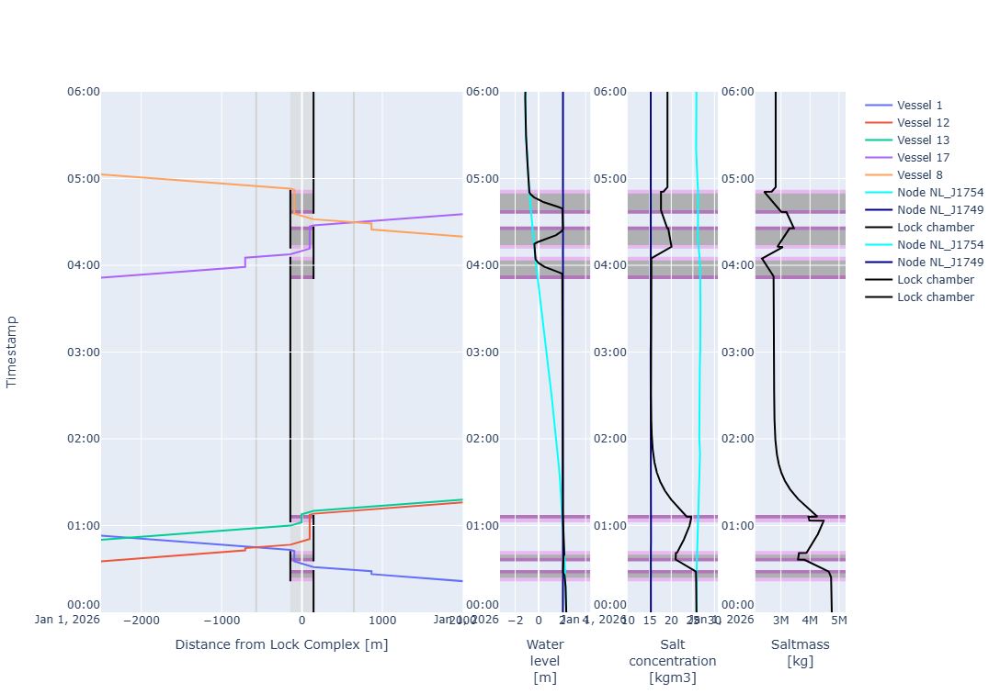

In [35]:
def cm_to_pixels(cm):
    return cm * 37.8 # Set figure height to 10 cmfig.update_layout(height=cm_to_pixels(10))

# We can plot the time-distance diagram
fig = lock_chambers['Westsluis'].plot(xlimmin = -2500, 
                                      xlimmax = 2000,
                                      ylimmin = pd.Timestamp('2026-01-01 00:00:00'),
                                      ylimmax = pd.Timestamp('2026-01-01 06:00:00'),
                                      method='Plotly',
                                      boundary_nodes = ['NL_J1986','NL_J0561']);

fig.update_layout(height=cm_to_pixels(20))

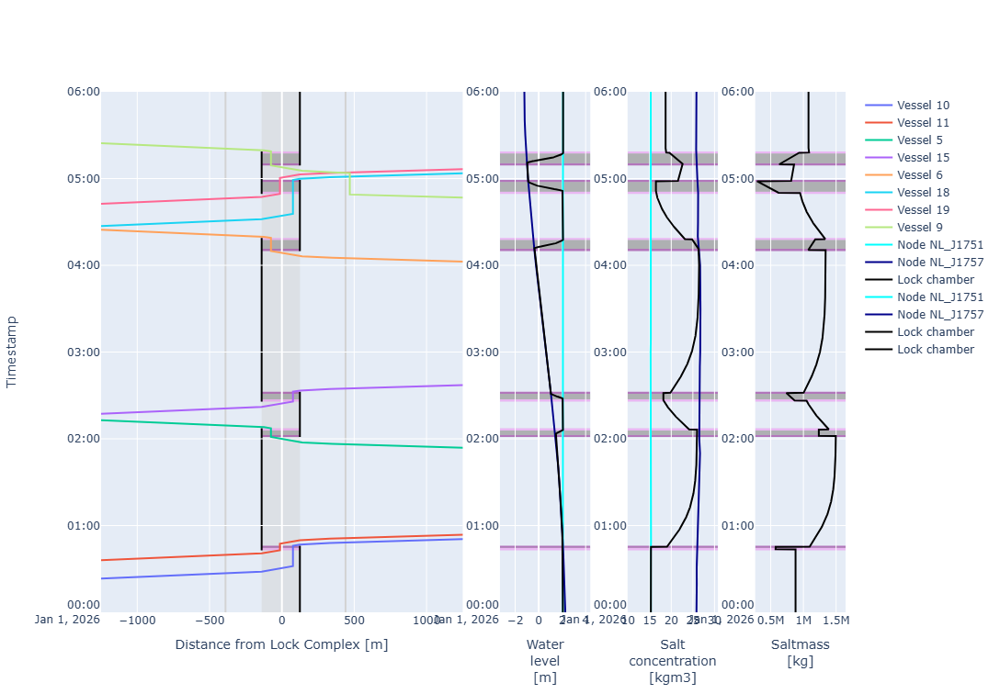

In [36]:
# We can plot the time-distance diagram
fig = lock_chambers['Oostsluis'].plot(xlimmin = -1250, 
                                      xlimmax = 1250,
                                      ylimmin = pd.Timestamp('2026-01-01 00:00:00'),
                                      ylimmax = pd.Timestamp('2026-01-01 06:00:00'),
                                      method='Plotly',
                                      boundary_nodes = ['NL_J1986','NL_J0561']);

fig.update_layout(height=cm_to_pixels(20))

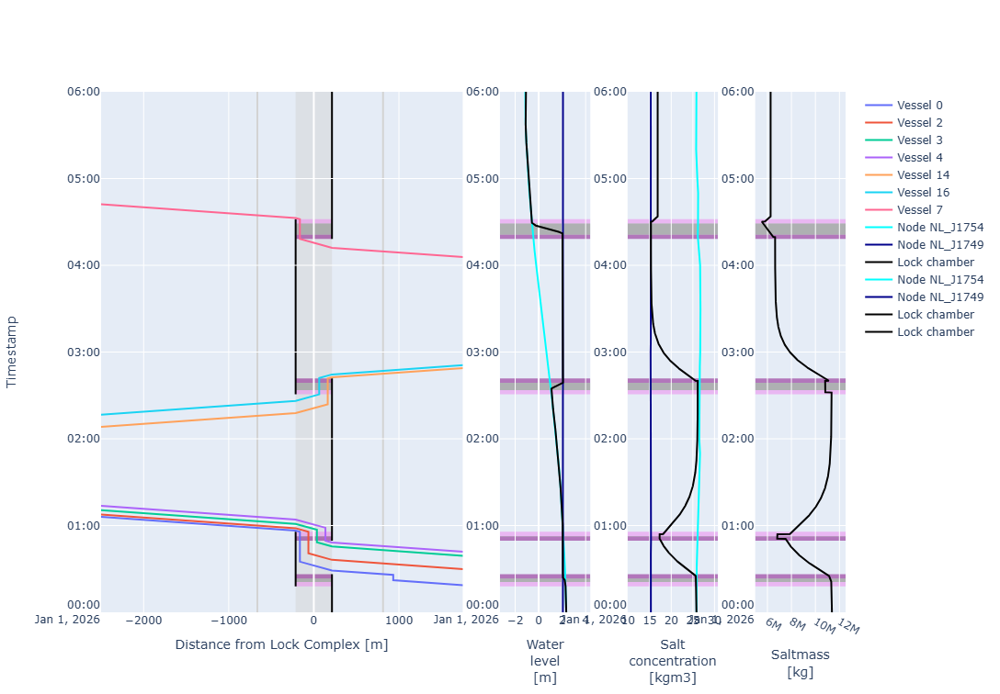

In [37]:
# We can plot the time-distance diagram
fig = lock_chambers['Nieuwe Sluis'].plot(xlimmin = -2500, 
                                      xlimmax = 1750,
                                      ylimmin = pd.Timestamp('2026-01-01 00:00:00'),
                                      ylimmax = pd.Timestamp('2026-01-01 06:00:00'),
                                      method='Plotly',
                                      boundary_nodes = ['NL_J1986','NL_J0561'])

fig.update_layout(height=cm_to_pixels(20))

##### Performance
We can assess the performance of each lock chamber individually:

In [38]:
performances_lock_chambers = {}
for lock_chamber_name, lock_chamber in lock_chambers.items():
    print(f'Performance {lock_chamber_name}')
    performances_lock_chambers[lock_chamber_name] = lock_chamber.get_performance()
    print('')

Performance Westsluis



Performance Oostsluis



Performance Nieuwe Sluis


Regarding saltwater intrusion, we observe that the larger the lock chamber, the greater the saltwater intrusion load flux. 
From these results, we can derive the total salt intrusion load flux on the channel, and which lock chambers are responsible for this:

In [39]:
param = 'Average saltwater intrusion flux [kg/s]'
chambers = ['Oostsluis', 'Westsluis', 'Nieuwe Sluis']

# Extract values
values = {
    chamber: performances_lock_chambers[chamber]['Average saltwater intrusion flux [kg/s]']
    for chamber in chambers
}

# Total
total_salt_intrusion_load = sum(values.values())

# Ratios w.r.t. total
ratios_salt_intrusion_load = {
    chamber: value / total_salt_intrusion_load
    for chamber, value in values.items()
}


sorted_ratios_salt_intrusion_load = sorted(ratios_salt_intrusion_load.items(), key=lambda x: x[1], reverse=True)

print(f'The total salt intrusion load flux of the Terneuzen lock complex is {np.round(total_salt_intrusion_load,1)} kg/s.')
print('The flux is caused by the:')
for name, value in sorted_ratios_salt_intrusion_load:
    print(f" - {name} ({value * 100:.1f}%)")

The total salt intrusion load flux of the Terneuzen lock complex is 706.0 kg/s.
The flux is caused by the:
 - Nieuwe Sluis (76.9%)
 - Westsluis (18.1%)
 - Oostsluis (5.1%)
